<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 16 · Mean-field Hubbard magnetism and Floquet engineering

* Hartree-Fock: $U n_\uparrow n_\downarrow \to U(\mathrm{Tr}\,\rho_i-\rho_i)$ per site (collinear and noncollinear).
* Floquet: $A(t)$ enters as a Peierls phase, and the high-frequency Hamiltonian is
  $H_{\rm eff}=H_0+\sum_{m>0}[H_m,H_{-m}]/m\omega$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import meanfield as MF, floquet as F

## 1. Antiferromagnetism of the honeycomb Hubbard model

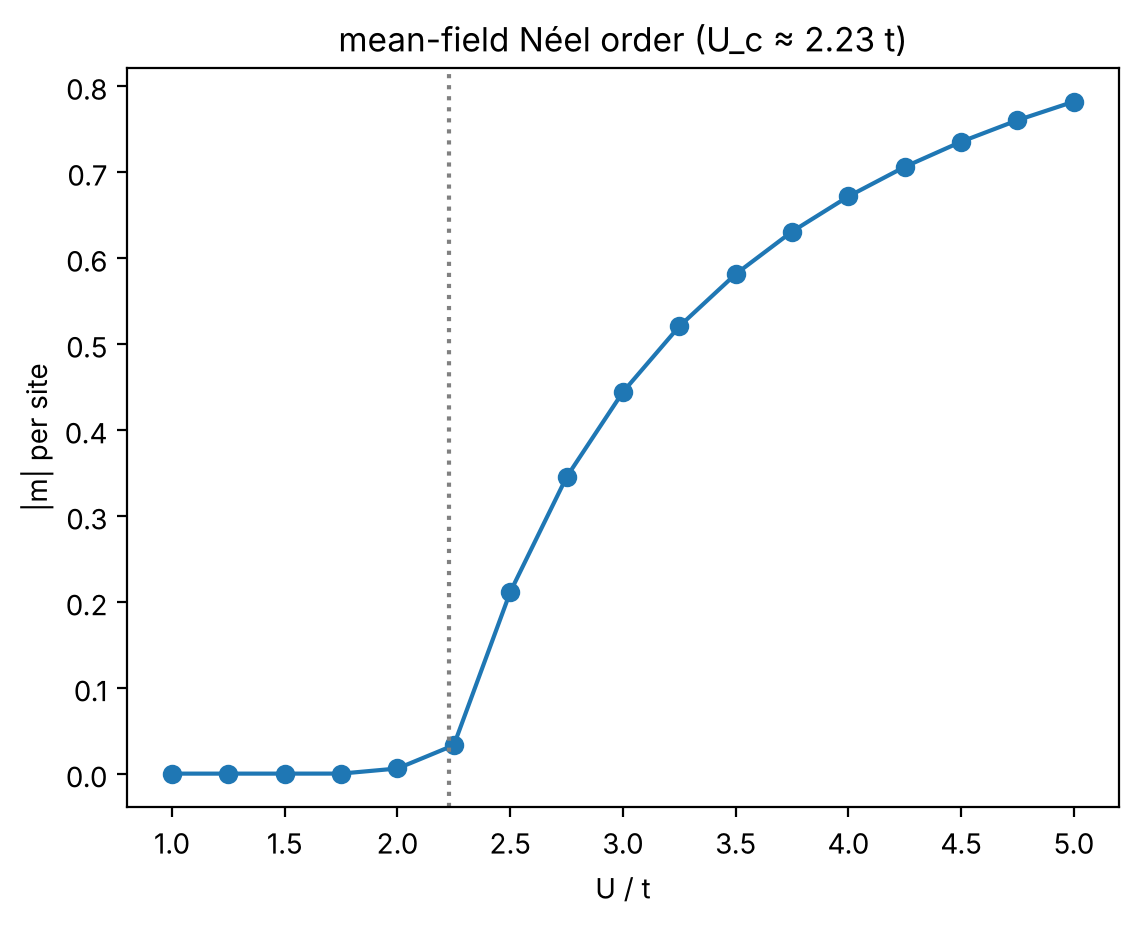

In [2]:
g = M.honeycomb().make_spinful()
Us = np.linspace(1.0, 5.0, 17)
res = MF.phase_diagram(g, Us, filling=0.5, init={"A": (0, 0, 1), "B": (0, 0, -1)}, nk=48, kT=0.002, maxiter=500)
plt.plot(Us, [abs(r.moments[0, 2]) for r in res], "o-"); plt.axvline(2.23, c="gray", ls=":")
plt.xlabel("U / t"); plt.ylabel("|m| per site"); plt.title("mean-field Néel order (U_c ≈ 2.23 t)");

<MeanFieldResult converged=True it=29 E=-1.282370 |m|max=0.7061>


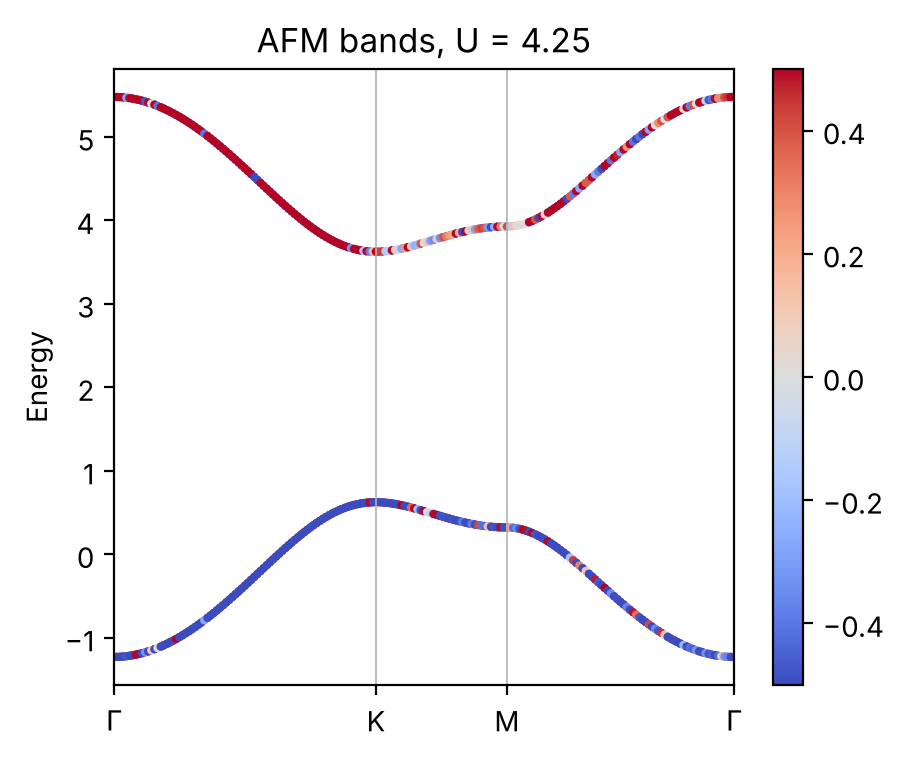

In [3]:
r = res[-4]
print(r)
r.model.plot_bands(["G", "K", "M", "G"], weights=r.model.spin_operator('z'), title=f"AFM bands, U = {Us[-4]:.2f}");

## 2. Square lattice: Néel order for any U, gap = U|m|

In [4]:
sq = M.square().make_spinful().supercell([[1, 1], [1, -1]])
for U in (1.0, 2.0, 4.0):
    r = MF.hubbard(sq, U, filling=0.5, init={0: (0, 0, 1), 1: (0, 0, -1)}, nk=60, kT=0.002, maxiter=600)
    print(f"U={U}: m={r.moments[0, 2]:+.4f}   gap={hf.band_gap(r.model, 2, 60):.4f}   U|m|={U*abs(r.moments[0, 2]):.4f}")

U=1.0: m=+0.1281   gap=0.1281   U|m|=0.1281


U=2.0: m=+0.3761   gap=0.7522   U|m|=0.7522


U=4.0: m=+0.6907   gap=2.7626   U|m|=2.7626


## 3. Ferromagnetism near a van Hove singularity (Stoner)

In [5]:
sq1 = M.square(t2=-0.3).make_spinful()
for U in (2.0, 4.0, 6.0):
    r = MF.hubbard(sq1, U, filling=0.3, init="ferro", nk=60, kT=0.005, maxiter=600)
    print(f"U={U}: m_z = {r.moments[0, 2]:.4f}  converged {r.converged}")

U=2.0: m_z = 0.0000  converged True


U=4.0: m_z = 0.3841  converged True
U=6.0: m_z = 0.6000  converged True


## 4. Floquet: light-induced Chern insulator in graphene

In [6]:
g0 = M.honeycomb()
K = g0.special_points["K"]
for A0 in (0.2, 0.4, 0.6):
    d = F.circular(A0, 10.0)
    print(f"A0={A0}: gap(K) eff={np.diff(F.EffectiveModel(g0, d).energies(K))[0]:.5f}  "
          f"exact={np.diff(F.FloquetModel(g0, d).quasienergies(K)[0])[0]:.5f}  "
          f"C={hf.chern_number(F.EffectiveModel(g0, d), 1, 40):+.0f}")
print("opposite helicity: C =", round(hf.chern_number(F.EffectiveModel(g0, F.circular(0.4, 10.0, -1)), 1, 40)))
print("linear polarisation: C =", round(hf.chern_number(F.EffectiveModel(g0, F.linear(0.4, 10.0)), 1, 40)))

A0=0.2: gap(K) eff=0.00598  exact=0.00598  C=+1
A0=0.4: gap(K) eff=0.02364  exact=0.02361  C=+1


A0=0.6: gap(K) eff=0.05220  exact=0.05207  C=+1
opposite helicity: C = -1
linear polarisation: C = 0


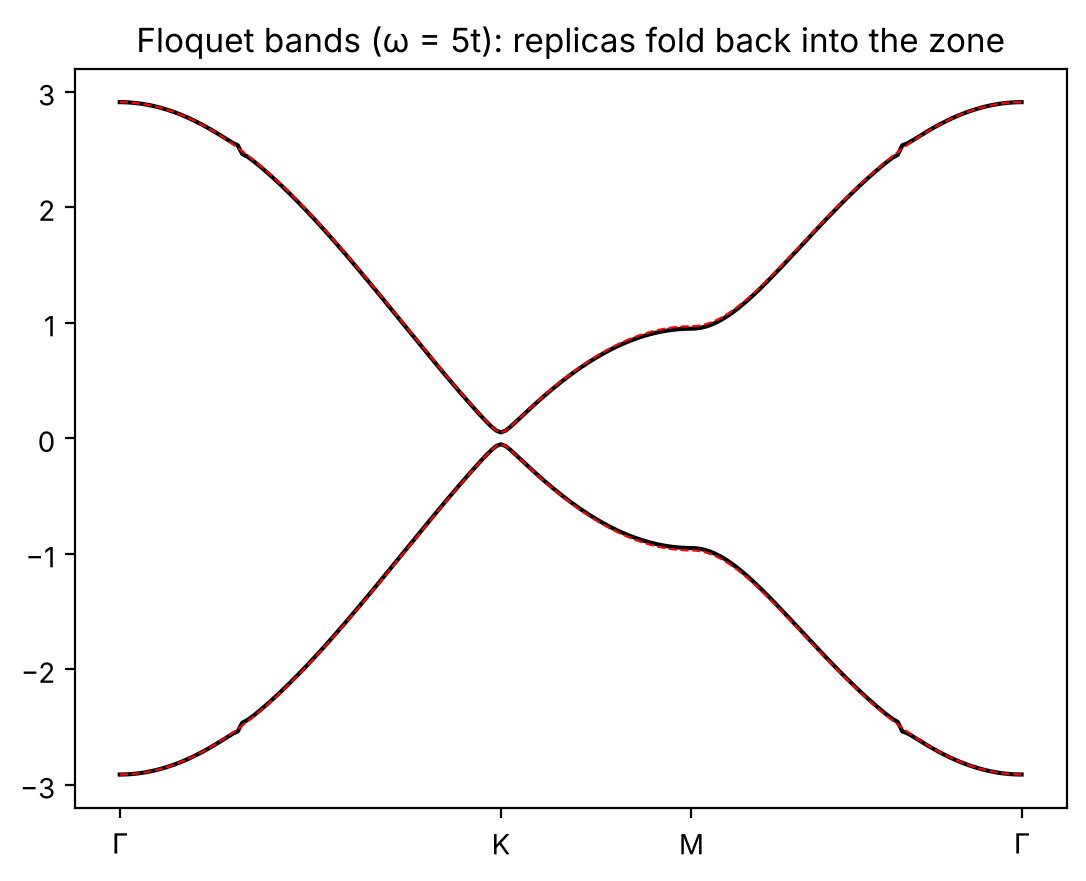

In [7]:
d = F.circular(0.6, 5.0)
Fl = F.FloquetModel(g0, d, n_max=4)
p = hf.kpath(g0, ["G", "K", "M", "G"], 200)
q = np.array([Fl.quasienergies(k)[0] for k in p.k])
Ee = F.EffectiveModel(g0, d).energies(p.k)
plt.plot(p.x, q, "k", label="exact quasienergies"); plt.plot(p.x, Ee, "r--", lw=0.8)
plt.xticks(p.ticks, p.labels); plt.ylim(-3.2, 3.2); plt.title("Floquet bands (ω = 5t): replicas fold back into the zone");

## 5. Floquet Hall conductivity (effective model)

In [8]:
Eff = F.EffectiveModel(g0, F.circular(1.0, 8.0))      # strong drive: gap ~ 0.1 t
print("gap at K:", np.diff(Eff.energies(K))[0], "  C =", round(hf.chern_number(Eff, 1, 60)))
print(hf.anomalous_hall(Eff, 0.0, 300, n_jobs=-1))

gap at K: 0.1705598980998186   C = 1


sigma^charge_xy = -1 [e^2/h]


## Exercises
1. Compute the mean-field phase diagram of the half-filled kagome Hubbard model (try ferro and 120° initial guesses on a supercell).
2. Find where the high-frequency expansion breaks down by comparing effective and exact gaps versus ω.
3. Drive the Kane-Mele model with circular light: can you obtain a spin-polarised quantum anomalous Hall phase?

---
## Quiz 16: Mean field and Floquet

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [9]:
quiz = hf.Quiz(16)
quiz.interactive()

In [10]:
quiz.show()

=== Quiz 16: Mean-field Hubbard magnetism and Floquet engineering ===

Q1. Hartree-Fock decoupling of U n_up n_dn gives the on-site potential
   (a) zero
   (b) U sigma_z always
   (c) U n
   (d) U (Tr rho - rho) in spin space

Q2. The mean-field critical U for AFM order of the half-filled honeycomb lattice is
   (a) about 2.23 t
   (b) 0
   (c) infinite
   (d) about 7 t

Q3. The half-filled square lattice orders antiferromagnetically
   (a) never
   (b) only at T > 0
   (c) for any U > 0 (perfect nesting, log-divergent susceptibility)
   (d) only above U = 4t

Q4. In collinear mean field the single-particle gap of the square AFM equals
   (a) t
   (b) U |m| (m = n_up - n_dn per site)
   (c) 0
   (d) U

Q5. To describe a Neel state on the square lattice you need
   (a) a ribbon
   (b) a sqrt(2) x sqrt(2) supercell (two sublattices)
   (c) spinless orbitals
   (d) one site

Q6. Mean-field theory typically
   (a) is exact in 2D
   (b) ignores spin
   (c) underestimates magnetism
   (d) o

In [11]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0